In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("crop_recommendation.csv")
data.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 2. Basic information

In [11]:
print("Rows and columns:", data.shape)
print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())
print("Number of crops:", data["label"].nunique())
data.describe()

Rows and columns: (2200, 8)
Missing values: 0
Duplicate rows: 0
Number of crops: 22


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


## 3. How many rows for each crop?
Every crop has 100 rows, so the data is balanced.

In [4]:
data["label"].value_counts()

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

## 4. Distribution of each feature

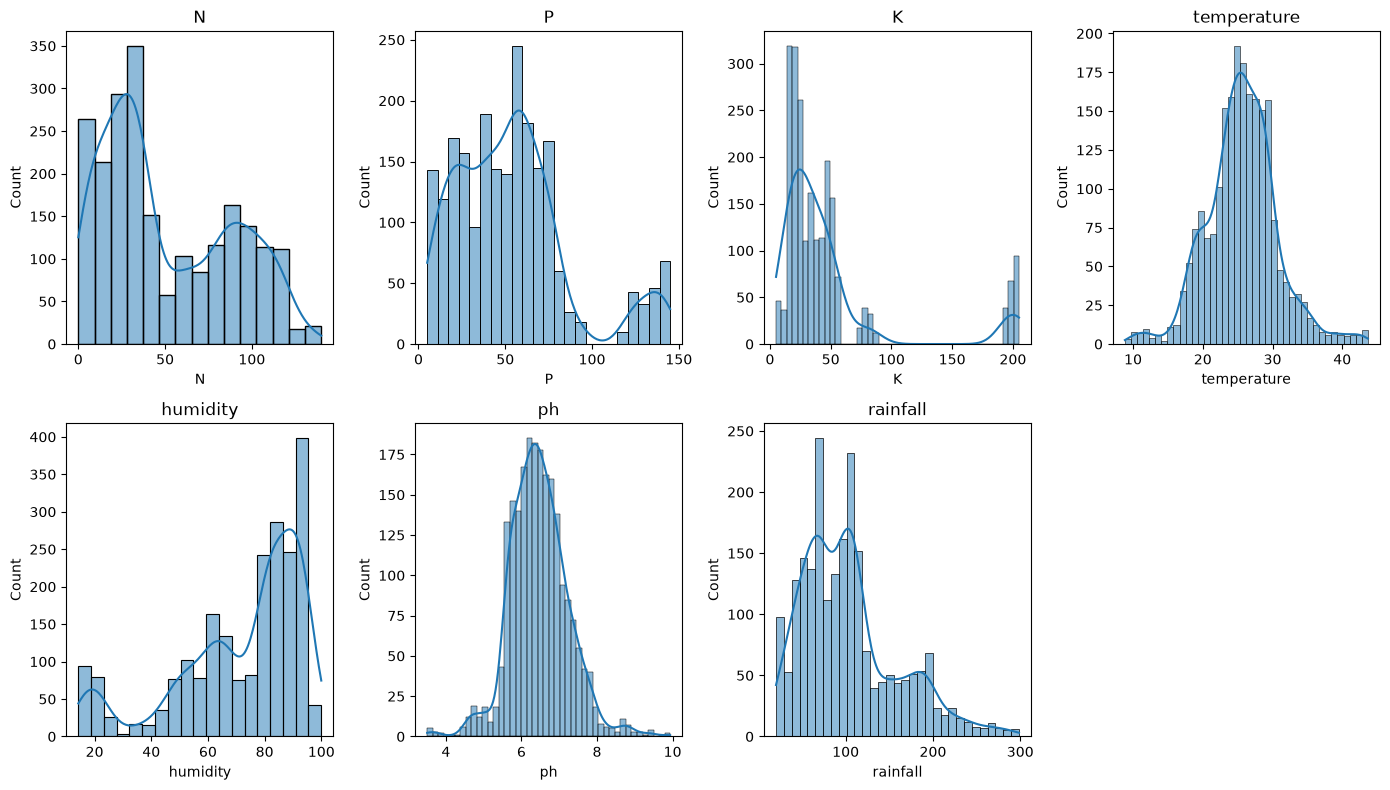

In [5]:
features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

plt.figure(figsize=(14, 8))
for i, col in enumerate(features):
    plt.subplot(2, 4, i + 1)
    sns.histplot(data[col], kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

## 5. Correlation between features
Values near 1 or -1 mean two features move together. Only P and K are strongly related (about 0.74). The others are weakly related.

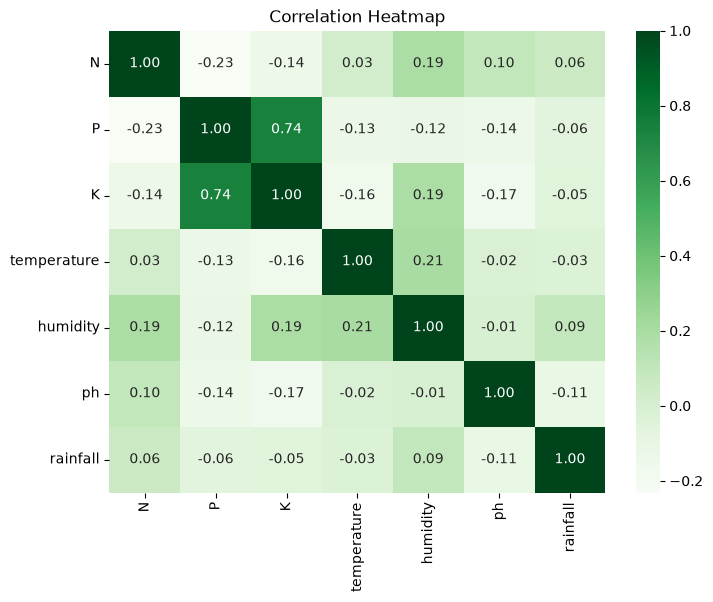

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(data[features].corr(), annot=True, fmt=".2f", cmap="Greens")
plt.title("Correlation Heatmap")
plt.show()

## 6. Average conditions for each crop

In [7]:
average = data.groupby("label")[features].mean().round(1)
average

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
apple,20.8,134.2,199.9,22.6,92.3,5.9,112.7
banana,100.2,82.0,50.0,27.4,80.4,6.0,104.6
blackgram,40.0,67.5,19.2,30.0,65.1,7.1,67.9
chickpea,40.1,67.8,79.9,18.9,16.9,7.3,80.1
coconut,22.0,16.9,30.6,27.4,94.8,6.0,175.7
coffee,101.2,28.7,29.9,25.5,58.9,6.8,158.1
cotton,117.8,46.2,19.6,24.0,79.8,6.9,80.4
grapes,23.2,132.5,200.1,23.8,81.9,6.0,69.6
jute,78.4,46.9,40.0,25.0,79.6,6.7,174.8


## 7. Rainfall for each crop
Rice needs the most rain (about 236 mm on average). Muskmelon, lentil, mungbean, watermelon and mothbeans need the least.

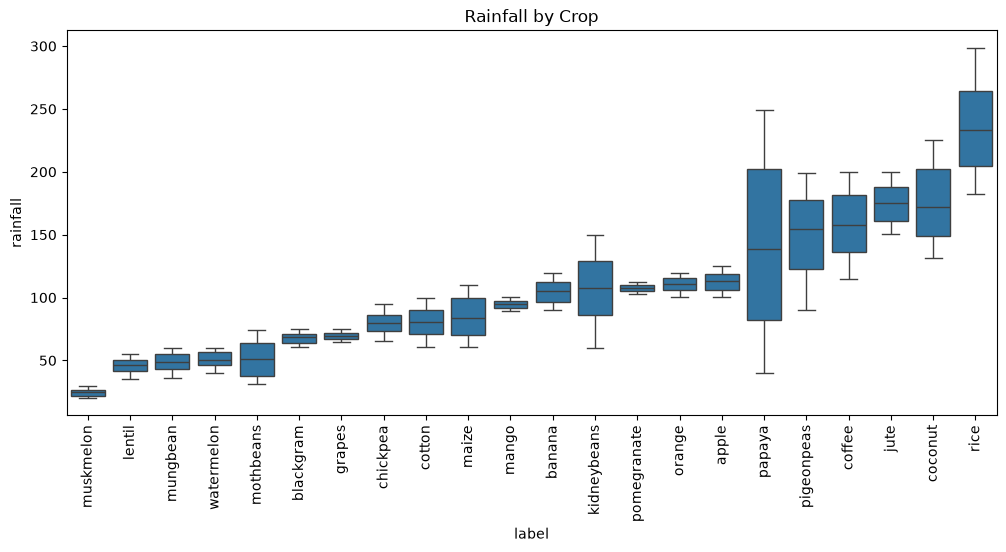

In [8]:
plt.figure(figsize=(12, 5))
order = data.groupby("label")["rainfall"].mean().sort_values().index
sns.boxplot(x="label", y="rainfall", data=data, order=order)
plt.xticks(rotation=90)
plt.title("Rainfall by Crop")
plt.show()

## 8. Temperature and humidity for each crop

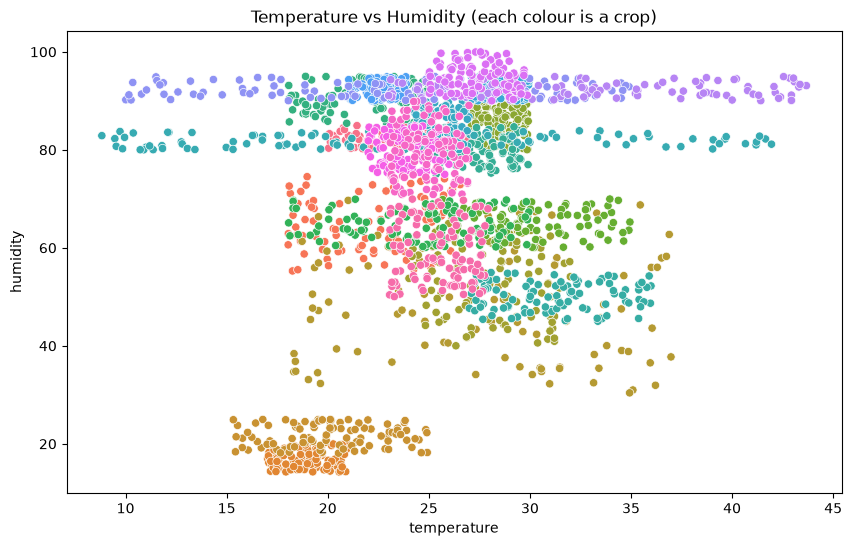

In [9]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x="temperature", y="humidity", hue="label", data=data, legend=False)
plt.title("Temperature vs Humidity (each colour is a crop)")
plt.show()

## 9. Which features matter most?
A Random Forest can tell us which input helped most in choosing the crop.

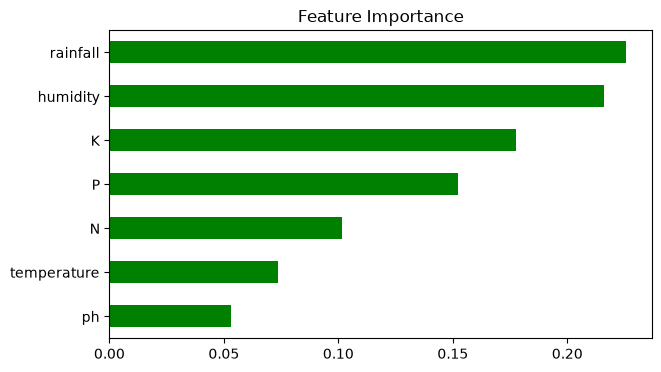

In [10]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(data[features], data["label"])

importance = pd.Series(rf.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", color="green", figsize=(7, 4))
plt.title("Feature Importance")
plt.show()